# Cookie Cats A/B Testi — 02: Keşifsel Analiz

Bu notebook'ta:
1. Veri hatası olan tek kaydı çıkarıyoruz ve temiz veriyi kaydediyoruz
2. Round dağılımına bakıyoruz (log ölçek)
3. Gruplara göre retention oranlarını karşılaştırıyoruz
4. Kapının oyuncu davranışını nasıl şekillendirdiğini görüyoruz

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter, MultipleLocator

pd.set_option("display.float_format", "{:.4f}".format)

# Grafik stili: sade eksenler, silik ızgara, metin gri tonlarında
COLORS = {"gate_30": "#2a78d6", "gate_40": "#eb6834"}   # kategorik slot 1 ve 2
SURFACE, INK, INK2, GRID = "#fcfcfb", "#1f1f1e", "#5f5e5a", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
FIG = "../figures/"
GROUPS = ["gate_30", "gate_40"]

## 1. Veri hatası olan kaydı çıkarma

Notebook 01'de verilen karar: **yalnızca 49.854 round oynayan tek oyuncu** çıkarılıyor (14 günde ≈ günde 3.500 round, fiziksel olarak mümkün değil → veri hatası).

Diğer yüksek değerler **tutuluyor**: `sum_gamerounds` deneyden etkilenen (post-treatment) bir değişken; ona göre filtrelemek gruplar arasında yanlılık yaratır ve kapıya en çok maruz kalan oyuncuları siler.

In [2]:
raw = pd.read_csv("../data/cookie_cats.csv")
bad = raw["sum_gamerounds"].idxmax()
display(raw.loc[[bad]])

df = raw.drop(index=bad).reset_index(drop=True)
print(f"Ham: {len(raw)} | Temiz: {len(df)} | Çıkarılan: {len(raw) - len(df)}")
df.to_csv("../data/cookie_cats_clean.csv", index=False)

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True


Ham: 90189 | Temiz: 90188 | Çıkarılan: 1


## 2. Round dağılımı

In [3]:
df.groupby("version")["sum_gamerounds"].describe(percentiles=[.25, .5, .75, .9, .99])

,count,mean,std,min,25%,50%,75%,90%,99%,max
version,,,,,,,,,,
gate_30,44699.0000,51.3421,102.0576,0.0000,5.0000,17.0000,50.0000,135.0000,493.0000,2961.0000
gate_40,45489.0000,51.2988,103.2944,0.0000,5.0000,16.0000,52.0000,134.0000,492.1200,2640.0000


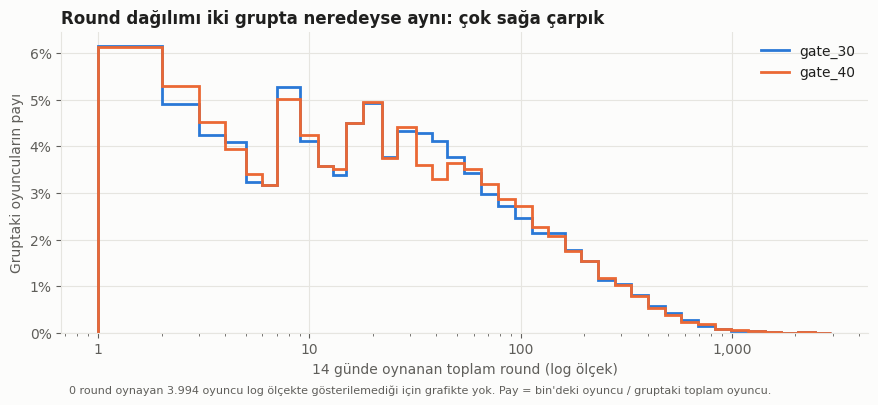

In [4]:
# Log aralıklı ama tam sayı sınırlı bin'ler (1, 2, 3... küçük değerlerde boş bin oluşmasın)
bins = np.unique(np.round(np.logspace(0, np.log10(df["sum_gamerounds"].max() + 1), 45)))
fig, ax = plt.subplots(figsize=(9, 4.2))
for g in GROUPS:
    x = df.loc[(df["version"] == g) & (df["sum_gamerounds"] > 0), "sum_gamerounds"]
    n_group = (df["version"] == g).sum()
    counts, edges = np.histogram(x, bins=bins)
    ax.stairs(counts / n_group, edges, color=COLORS[g], linewidth=2, label=g)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("14 günde oynanan toplam round (log ölçek)")
ax.set_ylabel("Gruptaki oyuncuların payı")
ax.set_title("Round dağılımı iki grupta neredeyse aynı: çok sağa çarpık")
ax.legend(loc="upper right")
ax.text(0.01, -0.2, "0 round oynayan 3.994 oyuncu log ölçekte gösterilemediği için grafikte yok. Pay = bin'deki oyuncu / gruptaki toplam oyuncu.",
        transform=ax.transAxes, fontsize=8, color=INK2)
fig.tight_layout(); fig.savefig(FIG + "01_round_dagilimi.png", dpi=150, bbox_inches="tight"); plt.show()

**Yorum:** Dağılım çok sağa çarpık: oyuncuların çoğu az oynuyor, küçük bir grup ise çok fazla oynuyor. Ortalama (~51) bu küçük grubun etkisiyle yukarı çekiliyor ve tipik oyuncuyu temsil etmiyor; medyan (16–17) temsil ediyor. Bu yüzden round karşılaştırmasında **medyan** raporlanacak ve gruplar ortalamaları değil sıraları kullanan **Mann-Whitney U** ile karşılaştırılacak.

## 3. Gruplara göre retention

In [5]:
ret = df.groupby("version")[["retention_1", "retention_7"]].agg(["mean", "sum", "count"])
summary = pd.DataFrame({
    "retention_1": ret[("retention_1", "mean")],
    "retention_7": ret[("retention_7", "mean")],
    "oyuncu": ret[("retention_1", "count")],
})
summary.loc["fark (40 − 30)"] = summary.loc["gate_40"] - summary.loc["gate_30"]
summary

,retention_1,retention_7,oyuncu
version,,,
gate_30,0.4482,0.1902,44699.0000
gate_40,0.4423,0.1820,45489.0000
fark (40 − 30),-0.0059,-0.0082,790.0000


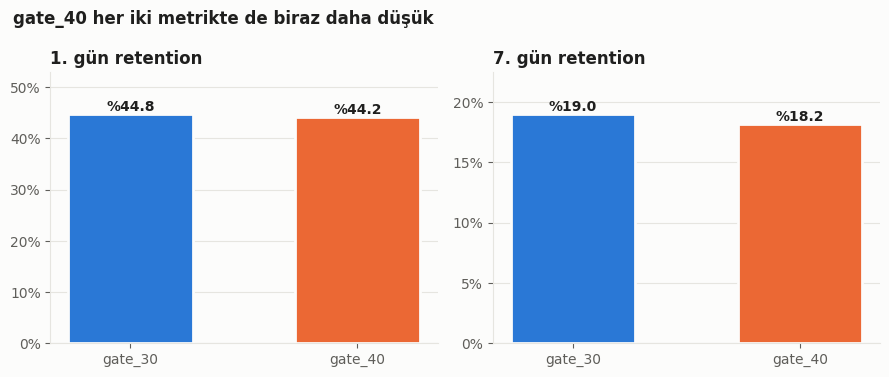

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=False)
for ax, metric, title in zip(axes, ["retention_1", "retention_7"], ["1. gün retention", "7. gün retention"]):
    vals = df.groupby("version")[metric].mean().reindex(GROUPS)
    bars = ax.bar(GROUPS, vals, color=[COLORS[g] for g in GROUPS], width=0.55,
                  edgecolor=SURFACE, linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"%{100*v:.1f}", ha="center", va="bottom",
                fontsize=10, color=INK, fontweight="bold")
    ax.set_title(title)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.yaxis.set_major_locator(MultipleLocator(0.1 if metric == "retention_1" else 0.05))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)
fig.suptitle("gate_40 her iki metrikte de biraz daha düşük", x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG + "02_retention_gruplar.png", dpi=150, bbox_inches="tight"); plt.show()

Mutlak farklar küçük görünüyor: retention_1'de ~0.6 puan, retention_7'de ~0.8 puan. Bu farkların şans eseri oluşup oluşmadığını **notebook 03'te** test edeceğiz. Bu aşamada sadece yön ve büyüklük hakkında fikir ediniyoruz.

**Yorum:** 0.8 puan mutlak olarak küçük görünse de göreli olarak 7. gün retention'da **~%4.3'lük** bir düşüş (0.82 / 19.02). Günde 100 bin yeni oyuncu gelen varsayımsal bir oyunda bu, her gün ~820 oyuncunun 7. günde geri dönmemesi demek. Bu yüzden fark iş açısından küçük sayılmaz; şans eseri olup olmadığı notebook 03'te test ediliyor.

## 4. Kapı oyuncu davranışını nasıl şekillendiriyor?

Her round sayısında oyuncuların ne kadarının durduğuna bakalım (1–100 round arası). Kapı oyuncuyu durduruyorsa, ilgili grupta kapının olduğu yer civarında bir **yığılma** görmeyi bekleriz.

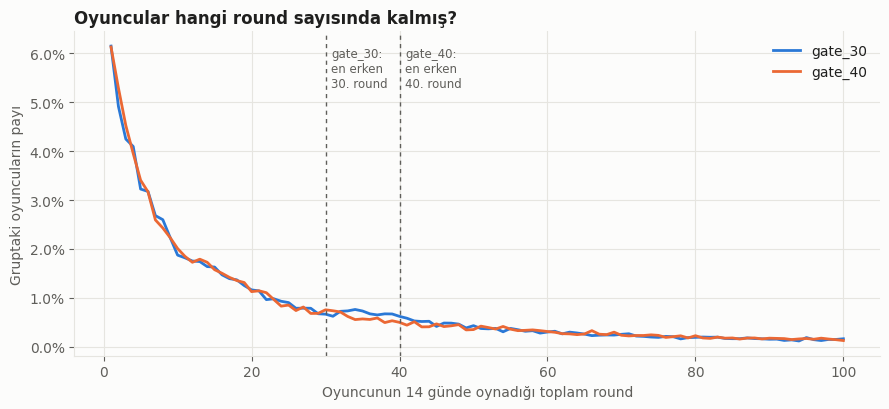

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for g in GROUPS:
    sub = df[df["version"] == g]
    share = sub["sum_gamerounds"].value_counts().reindex(range(1, 101), fill_value=0) / len(sub)
    ax.plot(share.index, share.values, color=COLORS[g], linewidth=2, label=g)
for lvl in (30, 40):
    ax.axvline(lvl, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
    ax.text(lvl + 0.8, ax.get_ylim()[1] * 0.95, f"gate_{lvl}:\nen erken\n{lvl}. round", color=INK2, fontsize=8.5, va="top")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xlabel("Oyuncunun 14 günde oynadığı toplam round")
ax.set_ylabel("Gruptaki oyuncuların payı")
ax.set_title("Oyuncular hangi round sayısında kalmış?")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG + "03_round_yigilma.png", dpi=150, bbox_inches="tight"); plt.show()

**Önemli: kapı level'da uygulanır, round'da değil.** Veride level bilgisi yok; bir level'ı geçemeyen oyuncu tekrar dener ve her deneme yeni bir round sayılır. Yani **level ≤ round**: 30 round oynamış oyuncu *en fazla* level 30'dadır. Dikey çizgiler kapının görülebileceği **en erken** noktayı gösterir; bu yüzden yığılma tam 30'da değil, sonrasına yayılmış olarak görünür. Aynı nedenle "≥30 round oynayanlar" oranı, kapıya ulaşanların yalnızca **üst sınırıdır**.

Aynı bilgiyi aralıklarla, retention_7 ile birlikte görelim:

In [8]:
edges = [-1, 0, 29, 39, 120, np.inf]
labels = ["0", "1–29", "30–39", "40–120", ">120"]
df["round_araligi"] = pd.cut(df["sum_gamerounds"], edges, labels=labels)
t = df.groupby(["round_araligi", "version"], observed=True)["retention_7"].agg(["size", "mean"]).unstack()
t.columns = [f"{a}_{b}" for a, b in t.columns]
t = t.rename(columns={"size_gate_30": "oyuncu_30", "size_gate_40": "oyuncu_40",
                      "mean_gate_30": "ret7_30", "mean_gate_40": "ret7_40"})
t["ret7_fark"] = t["ret7_40"] - t["ret7_30"]
t

,oyuncu_30,oyuncu_40,ret7_30,ret7_40,ret7_fark
round_araligi,,,,,
0,1937,2057,0.0083,0.0063,-0.0019
1–29,26107,26819,0.0451,0.0418,-0.0033
30–39,3090,2786,0.1573,0.1569,-0.0004
40–120,8504,8712,0.3530,0.3284,-0.0246
>120,5061,5115,0.7546,0.7519,-0.0027


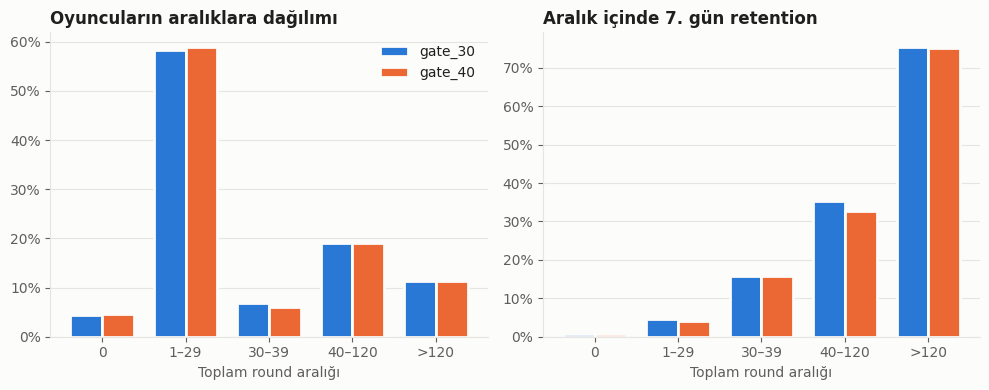

In [9]:
x = np.arange(len(labels)); w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
n30 = (df["version"] == "gate_30").sum(); n40 = (df["version"] == "gate_40").sum()
for ax, (col30, col40, title, scale) in zip(axes, [
        ("oyuncu_30", "oyuncu_40", "Oyuncuların aralıklara dağılımı", (n30, n40)),
        ("ret7_30", "ret7_40", "Aralık içinde 7. gün retention", (1, 1))]):
    for i, (col, g, s) in enumerate([(col30, "gate_30", scale[0]), (col40, "gate_40", scale[1])]):
        ax.bar(x + (i - 0.5) * w, t[col] / s, w, color=COLORS[g], label=g, edgecolor=SURFACE, linewidth=2)
    ax.set_xticks(x, labels); ax.set_xlabel("Toplam round aralığı")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG + "04_aralik_retention.png", dpi=150, bbox_inches="tight"); plt.show()

**Yorum:**
- 30–39 round aralığında gate_30 grubunda daha çok oyuncu var, çünkü bu oyuncular kapıya takılıp orada durmuş. Bu, kapının oyuncu davranışını mekanik olarak şekillendirdiğini gösteriyor.
- retention_7 farkı en çok 40–120 round aralığında ortaya çıkıyor (−2.5 puan); bu, etkinin kapıyı gerçekten gören oyuncularda yoğunlaştığına dair bir **ipucu**.
- **Ancak bu tablo nedensel yorumlanamaz.** Aralıklar deneyden etkilenen bir değişkene göre oluşturuldu: gate_30'da 40+ round oynayan oyuncu kapıyı zaten geçmiş, daha sadık bir alt küme; gate_40'ta aynı aralıktaki oyuncuların bir kısmı kapıya yeni çarpmış. İki grubun aynı aralığı farklı türde oyunculardan oluşuyor (seçilim etkisi). Nedensel sonuç, notebook 03'teki tüm grupların karşılaştırmasından çıkarılacak.

## Keşifsel analiz özeti

- Round dağılımı çok çarpık (medyan 16–17, ortalama ~51) ve iki grupta neredeyse aynı.
- gate_40 her iki retention metriğinde de daha düşük: retention_1'de −0.6, retention_7'de −0.8 puan.
- Oyuncuların çoğu kapıya hiç ulaşmıyor: en fazla %37'si 30 round oynamış. Kapı etkisi, kapıya ulaşan oyuncularda yoğunlaşıyor gibi görünüyor.
- Notebook 03'te test edilecek hipotezler: iki grup arasında retention_7 (ana), retention_1 ve round sayısı açısından fark var mı?